# ERCOT Forecasting Regional Electricity Grid Demand

## Project Overview
The purpose of this notebook is to build and evaluate a model that will predict electricy grid demand in Texas. This model will use historical data from the U.S. Energy Information Administration's EIA-930 reporting system. The dataset covers January 2022 through September 2026 and includes actual electricty demand, ERCOT's day-ahead demand forecast and engineered features that will support forecasting. 

## Project Objective
The primary objective of this project is to develop a model that predicts electricity demand one day ahead and evaluate its performance against ERCOT's existing day-ahead forecast. 

## 1. Review Prepared Data 

This is not the intial EDA, as the data has already been cleaned and some feature engineering has been performed on it. The purpose of this section is to gain a general understanding of the engineered data before building a model. 

I will make any additional cleaning/engineering changes here as well. 


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('eia930_erco_cleaned.csv')

In [7]:
df.head()

,period_utc,demand_mwh,demand_forecast_mwh,net_generation_mwh,interchange_mwh,was_missing_hour,demand_raw_mwh,demand_imputed,period_central,hour,day_of_week,is_weekend,month,year,season,is_holiday,demand_lag_24,demand_lag_168,demand_roll_mean_24,ercot_forecast_error_mwh
0,2022-01-01 00:00:00+00:00,45943.0,44669.0,45659.0,-284.0,0,45943.0,0,2021-12-31 18:00:00-06:00,18,4,0,12,2021,Winter,1,NaN,NaN,NaN,-1274.0
1,2022-01-01 01:00:00+00:00,46427.0,44468.0,46255.0,-172.0,0,46427.0,0,2021-12-31 19:00:00-06:00,19,4,0,12,2021,Winter,1,NaN,NaN,NaN,-1959.0
2,2022-01-01 02:00:00+00:00,45058.0,42466.0,44985.0,-73.0,0,45058.0,0,2021-12-31 20:00:00-06:00,20,4,0,12,2021,Winter,1,NaN,NaN,NaN,-2592.0
3,2022-01-01 03:00:00+00:00,43430.0,40562.0,43449.0,19.0,0,43430.0,0,2021-12-31 21:00:00-06:00,21,4,0,12,2021,Winter,1,NaN,NaN,NaN,-2868.0
4,2022-01-01 04:00:00+00:00,42058.0,39027.0,42136.0,79.0,0,42058.0,0,2021-12-31 22:00:00-06:00,22,4,0,12,2021,Winter,1,NaN,NaN,NaN,-3031.0


In [8]:
df.shape

(41616, 20)

In [9]:
df.dtypes

period_utc                   object
demand_mwh                  float64
demand_forecast_mwh         float64
net_generation_mwh          float64
interchange_mwh             float64
was_missing_hour              int64
demand_raw_mwh              float64
demand_imputed                int64
period_central               object
hour                          int64
day_of_week                   int64
is_weekend                    int64
month                         int64
year                          int64
season                       object
is_holiday                    int64
demand_lag_24               float64
demand_lag_168              float64
demand_roll_mean_24         float64
ercot_forecast_error_mwh    float64
dtype: object

In [10]:
# Convert timestamp columns to datetime
df["period_utc"] = pd.to_datetime(df["period_utc"], utc=True)
df["period_central"] = pd.to_datetime(df["period_central"])

# Verify the changes
print(df[["period_utc", "period_central"]].dtypes)

period_utc        datetime64[ns, UTC]
period_central                 object
dtype: object


/var/folders/82/fp9kfdvn2ts8x2vwd08qhxtm0000gn/T/ipykernel_2002/3927463764.py:3: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df["period_central"] = pd.to_datetime(df["period_central"])


In [11]:
# Check for missing values
print("Total missing values:", df.isna().sum().sum())

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate timestamps
print("Duplicate timestamps:", df["period_utc"].duplicated().sum())

# Check for impossible demand values
print("Zero or negative demand values:", (df["demand_mwh"] <= 0).sum())


Total missing values: 630
Duplicate rows: 0
Duplicate timestamps: 0
Zero or negative demand values: 0


### Target Variable: 'demand_mwh'

This section will explore the target variable.

In [12]:

# Descriptive statistics for actual electricity demand
df["demand_mwh"].describe()


count    41616.000000
mean     53422.986976
std      11574.551836
min      31949.000000
25%      44748.000000
50%      50665.000000
75%      60380.250000
max      91075.000000
Name: demand_mwh, dtype: float64

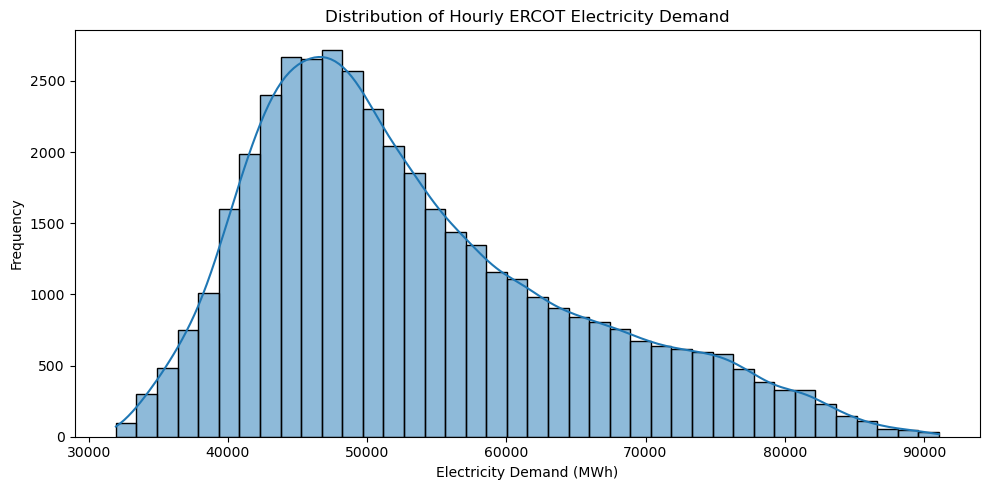

In [13]:

# Distribution of hourly electricity demand
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="demand_mwh", bins=40, kde=True)

plt.title("Distribution of Hourly ERCOT Electricity Demand")
plt.xlabel("Electricity Demand (MWh)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


#### Descriptive Statistics Findings

The dataset contains 41,616 hourly electricity demand observations. Demand averages approximately 53,423 MWh, with a standard deviation of approximately 11,575 MWh. Observed demand ranges from 31,949 MWh to 91,075 MWh, while the middle 50% of observations fall between 44,748 MWh and 60,380 MWh.

The histogram shows a right-skewed distribution, with most observations concentrated at moderate demand levels and fewer observations at higher demand levels. The mean being greater than the median supports this observation.

These findings indicate substantial variation in electricity demand. The forecasting models should therefore be evaluated on their ability to predict demand across both typical and high-demand periods. The next stage of the analysis will examine how demand changes over time.

### Electricity Over Time

A time-series plot is used to examine how ERCOT electricity demand changes throughout the dataset. The goal of this visual is to identify long-term trends, fluctutations in demand, and periods of unusually high or low energy consumption.

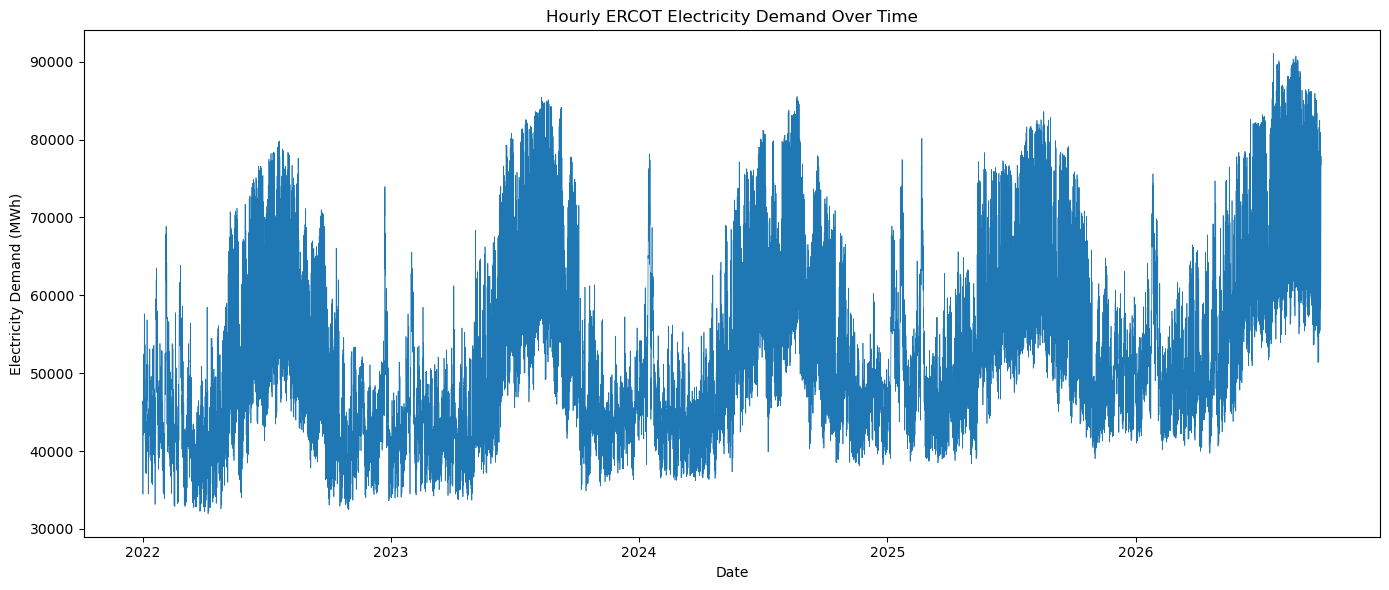

In [14]:

# Plot hourly electricity demand over time
plt.figure(figsize=(14, 6))

plt.plot(df["period_utc"], df["demand_mwh"], linewidth=0.5)

plt.title("Hourly ERCOT Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MWh)")
plt.tight_layout()
plt.show()


#### Observations

There are strong recurring seasonal patterns as shown by broad peaks that are consistent with seasonal demand. Demand appears to show a slight increase over time. This could affect how data is split into training and testing data. 

### Average Demand by Month

This section will explore monthly electricity demand patterns to identify seasonal patterns. This will determine the usefulness of calendar based features for predicting ERCOT's day-ahead electricity demand. 

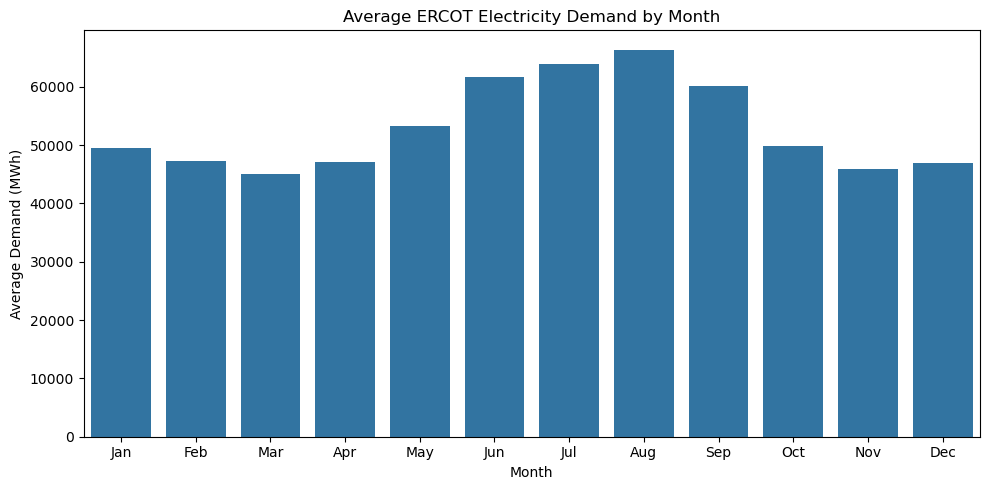

In [15]:

# Calculate average demand for each month
monthly_demand = df.groupby("month")["demand_mwh"].mean()

# Plot average demand by month
plt.figure(figsize=(10, 5))

sns.barplot(x=monthly_demand.index, y=monthly_demand.values)

plt.title("Average ERCOT Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand (MWh)")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
plt.tight_layout()
plt.show()



#### Observations

The chart shows a clear seasonal pattern. Demand rises in late spring/early summer and remains elevated until October. This supports the idea that there is substantial seasonal differences in energy demands. Based on this information, calendar features will be retained as predictors for modeling. 

### Evaluate Model Readiness

This section will be a final check to evaluate whether the predictor features and target variable are ready for modeling.

Current Features Roles:
- target variable 'demand_mwh'
- candidate predictors 'hour', 'day_of_week', 'is_weekend', 'month', 'year', 'season', 'is_holiday', 'demand_lag_24', 'demand_lag_168', 'demand_roll_mean_24'
- evaluation features 'demand_forecast_mwh', 'ercot_forecast_error_mwh'

## 2. Prepare Data For Modeling

This section prepares the cleaned and engineered dataset for forecasting. The intial steps focus on verifying the availability of historical demand features and removing observations that cannot be used because they lack the required lag values. 

The dataset will then be divided into chronilogical training and testing data to evaluate how well the forecasting models predict future electricity demand. 

### Drop First 168 Columns

In [16]:
# Review missing values in the historical demand features
lag_features = [
    'demand_lag_24',
    'demand_lag_168',
    'demand_roll_mean_24'
]

df[lag_features].isna().sum()

demand_lag_24           24
demand_lag_168         168
demand_roll_mean_24     47
dtype: int64

In [17]:
# remove the first 168 observations
df_model = df.iloc[168:].copy()

# confirm number of remaining rows
print(f'Original Rows: {len(df)}')
print(f'Rows after removing initial 168: {len(df_model)}')

Original Rows: 41616
Rows after removing initial 168: 41448


### Training/Test Split

The data will be split into training and testing data. The training data will be used to fit the models. The testing data will be used to evalute the model after initial evaluation and tuning have been completed. 

Training Data: January 2022 through September 2025
Testing Data: October 2025 through September 2026

In [18]:
# define training and testing periods
train = df_model[
    df_model['period_utc'] < '2025-10-01'
].copy()

test = df_model[
    df_model['period_utc'] >= '2025-10-01'
].copy()

# verify the split
print(f'Training Observations: {len(train)}')
print(f'Training Period: {train['period_utc'].min()} to {train['period_utc'].max()}')
print(f'Testing Observations: {len(test)}')
print(f'Testing Period: {test['period_utc'].min()} to {test['period_utc'].max()}')



Training Observations: 32688
Training Period: 2022-01-08 00:00:00+00:00 to 2025-09-30 23:00:00+00:00
Testing Observations: 8760
Testing Period: 2025-10-01 00:00:00+00:00 to 2026-09-30 23:00:00+00:00


## 3. Seasonal Naive Baseline Model

This model will serve as a baseline for evaluating the more advanced forecasting models. It predicts electricity grid demand by using the observed demand from the same hour one week earlier. This model will make predictions using the test data so comparisons can be made with more complex models later. 

In [19]:
# actual demand values
y_test = test['demand_mwh']

# seasonal naive predictions
qhat = test['demand_lag_168']

# compare actual demand with predicted demand
display(pd.DataFrame({
    'Actual Demand (MWh)': y_test.head(),
    'Predicted Demand (MWh)': qhat.head()
}))

,Actual Demand (MWh),Predicted Demand (MWh)
32856,71339.0,77934.0
32857,68196.0,75578.0
32858,65836.0,73851.0
32859,62418.0,70695.0
32860,58073.0,67790.0


### Evaluate Seasonal Naive Baseline

The MAE, RMSE and MAPE will be used to evaluate the baseline model. 

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

base_mae = mean_absolute_error(y_test, qhat)

base_rmse = np.sqrt(mean_squared_error(y_test, qhat))

base_mape = np.mean(np.abs((y_test - qhat) / y_test)) * 100

print(f'Baseline MAE: {base_mae:,.2f} MWh')
print(f'Baseline RMSE: {base_rmse:,.2f} MWh')
print(f'Baseline MAPE: {base_mape:,.2f}%')


Baseline MAE: 4,188.83 MWh
Baseline RMSE: 5,715.88 MWh
Baseline MAPE: 7.43%


#### Interpretation

The baseline predictions differ from actual demand by about 4189 MWh on average or 7.43% on average relative to actual demand. 

The RMSE is higher than MAE, suggesting that some larger prediction errors are affecting the results.

## 4. SARIMA Model

A SARIMA model is a time-series forecasting model that accounts for trends, changes over time, and recurring seasonal patterns. It will be used to forecast hourly electricity demand in the ERCOT region. The model will be trained using historical electricity demand from January 2022 to September 2025 and evaluated on the test period from October 2025 to September 2026. 

This model will be compared to the Seasonal Naive Baseline Model to determine whether it improves accuracy. 

In [21]:
# Use the most recent three years of training data
sarima_train = train.loc[
    train['period_utc'] >= '2022-10-01'
].copy()

# Prepare the hourly demand series
train_demand = sarima_train.set_index('period_utc')['demand_mwh']

print(f'Number of training observations: {len(train_demand)}')
print(f'Missing demand values: {train_demand.isna().sum()}')
print(f'Start date: {train_demand.index.min()}')
print(f'End date: {train_demand.index.max()}')

Number of training observations: 26304
Missing demand values: 0
Start date: 2022-10-01 00:00:00+00:00
End date: 2025-09-30 23:00:00+00:00


In [22]:
# Check the training time series
print(f'Number of observations: {len(train_demand)}')
print(f'Missing demand values: {train_demand.isna().sum()}')
print(f'Duplicate timestamps: {train_demand.index.duplicated().sum()}')
print(f'Chronologically ordered: {train_demand.index.is_monotonic_increasing}')
print(f'Frequency: {train_demand.index.inferred_freq}')

Number of observations: 26304
Missing demand values: 0
Duplicate timestamps: 0
Chronologically ordered: True
Frequency: h


In [23]:
# Prepare the test demand series
test_demand = test.set_index('period_utc')['demand_mwh']

print(f'Test observations: {len(test_demand)}')
print(f'Missing demand values: {test_demand.isna().sum()}')
print(f'Start date: {test_demand.index.min()}')
print(f'End date: {test_demand.index.max()}')

Test observations: 8760
Missing demand values: 0
Start date: 2025-10-01 00:00:00+00:00
End date: 2026-09-30 23:00:00+00:00


In [24]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# define intial SARIMA model
sarima_model = SARIMAX(
    train_demand,
    order=( 1, 1, 1),
    seasonal_order=(0, 1, 0, 24)
)

# fit the SARIMA model
sarima_results = sarima_model.fit()

/opt/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


In [25]:

# Initial SARIMA Experiment: Full-Year Static Forecast
# This approach produced unrealistic predictions that drifted upward.
# The original model was trained on two years of data.
# Code is preserved for documentation and should not be rerun.

# sarima_forecast = sarima_results.get_forecast(steps=len(test))
# qhat_sarima = sarima_forecast.predicted_mean

# Original reported results:
# MAE: approximately 966,203 MWh
# RMSE: approximately 1,111,229 MWh
# MAPE: NaN


In [26]:
# generate predictions
sarima_forecast = sarima_results.get_forecast(
    steps=len(test)
)

qhat_sarima = sarima_forecast.predicted_mean

print(f'Number of SARIMA predictions: {len(qhat_sarima)}')
print(f'Number of test observations: {len(test)}')

Number of SARIMA predictions: 8760
Number of test observations: 8760


In [27]:

rolling_results = sarima_results
rolling_predictions = []

for start in range(0, len(test_demand), 24):
    forecast = rolling_results.get_forecast(steps=24)
    qhat_day = forecast.predicted_mean

    rolling_predictions.extend(qhat_day.to_list())

    actual_day = test_demand.iloc[start:start + 24]

    rolling_results = rolling_results.append(
        actual_day,
        refit=False
    )

    if (start // 24 + 1) % 30 == 0:
        print(f'Completed day {start // 24 + 1} of {len(test_demand) // 24}')

qhat_sarima_rolling = pd.Series(
    rolling_predictions,
    index=test_demand.index,
    name='SARIMA_Rolling_Prediction'
)



Completed day 30 of 365
Completed day 60 of 365
Completed day 90 of 365
Completed day 120 of 365
Completed day 150 of 365
Completed day 180 of 365
Completed day 210 of 365
Completed day 240 of 365
Completed day 270 of 365
Completed day 300 of 365
Completed day 330 of 365
Completed day 360 of 365


In [28]:

print(f'Number of predictions: {len(qhat_sarima_rolling)}')
print(f'Missing predictions: {qhat_sarima_rolling.isna().sum()}')
print(f'Infinite predictions: {np.isinf(qhat_sarima_rolling).sum()}')
print(f'Index matches test data: {qhat_sarima_rolling.index.equals(test_demand.index)}')
print(f'First prediction: {qhat_sarima_rolling.iloc[0]:,.2f}')
print(f'Last prediction: {qhat_sarima_rolling.iloc[-1]:,.2f}')


Number of predictions: 8760
Missing predictions: 0
Infinite predictions: 0
Index matches test data: True
First prediction: 72,114.91
Last prediction: 78,368.56


### Evalulate Rolling SARIMA Metrics

In [29]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

sarima_mae_3yr = mean_absolute_error(
    test_demand, qhat_sarima_rolling
)

sarima_rmse_3yr = np.sqrt(
    mean_squared_error(test_demand, qhat_sarima_rolling)
)

sarima_mape_3yr = (
    np.abs((test_demand - qhat_sarima_rolling) / test_demand).mean() * 100
)

print(f'3-Year SARIMA MAE: {sarima_mae_3yr:,.2f} MWh')
print(f'3-Year SARIMA RMSE: {sarima_rmse_3yr:,.2f} MWh')
print(f'3-Year SARIMA MAPE: {sarima_mape_3yr:.2f}%')


3-Year SARIMA MAE: 2,659.02 MWh
3-Year SARIMA RMSE: 3,727.97 MWh
3-Year SARIMA MAPE: 4.86%


### SARIMA Model Interpretation

#### Model Configuration and Training Data

The final model used an order of (1, 1, 1) and a seasonal order of (0, 1, 0, 24). The seasonal period of 24 represents the daily cycle in hourly electricity demand. The model was trained using three years of hourly demand data, from October 1, 2022, through September 30, 2025, consisting of 26,304 observations.

#### Forecasting Approach

An initial experiment attempted to forecast the entire test year in a single operation. However, the predictions increased dramatically over the forecast horizon, eventually approaching 2 million MWh. The resulting errors were extremely large, indicating that this static forecasting approach did not produce reliable long-horizon predictions.

To address this issue, the forecasting procedure was changed to a rolling day-ahead approach. The model forecasts the next 24 hours, incorporates the actual demand observed during those hours, and then forecasts the following 24 hours. The model parameters are not refitted each day; instead, the model state is updated with the newly observed demand.

The rolling approach generated 8,760 predictions for the test period from October 1, 2025, through September 30, 2026. The predictions contained no missing or infinite values and were correctly aligned with the actual demand observations.

#### Model Evaluation

The MAE indicates that the model's predictions differed from actual hourly demand by an average absolute amount of approximately 2,659 MWh. The RMSE was approximately 3,728 MWh. Because RMSE penalizes larger errors more heavily than MAE, the difference between these metrics suggests that some forecast errors were larger than the typical absolute error.

The MAPE of 4.86% indicates that the model's average absolute percentage error was approximately 4.86% across the test observations.

#### Comparison with the Seasonal-Naive Baseline

The seasonal-naive baseline predicted demand using the observed demand from the same hour one week earlier. Its evaluation results were an MAE of 4,188.83 MWh, an RMSE of 5,715.88 MWh, and a MAPE of 7.43%.

Compared with this baseline, the three-year SARIMA model achieved approximately 36.5% lower MAE, 34.8% lower RMSE, and 34.6% lower MAPE. These results indicate that SARIMA captured useful patterns in electricity demand beyond those represented by the seasonal-naive benchmark.

Although the SARIMA model performed better on all three metrics, the comparison should be interpreted in the context of each method's forecasting procedure. The SARIMA model uses daily 24-hour forecast batches, while the seasonal-naive baseline uses demand from the corresponding hour one week earlier.

#### Conclusion

The three-year SARIMA model successfully generated hourly day-ahead forecasts across the full test year. Its performance was substantially better than the seasonal-naive baseline, suggesting that a time-series model can provide useful forecasts of ERCOT electricity demand.

The earlier full-year static forecasting experiment also demonstrated the importance of selecting an appropriate forecasting procedure. Updating the model state with actual observations each day produced a more practical forecasting approach than attempting to generate the entire year's predictions at once.

Overall, SARIMA provides a useful benchmark for the project. Its results can be compared with the other forecasting models and the ERCOT day-ahead demand forecast to determine which approach provides the most accurate predictions.

## 5. Prophet Model

A Prophet model is designed to model time-series data with trends, seasonality and recurring patterns. This will be useful for forecasting electricity demand because energy consumption varies over hours, days, and seasons. 

This model will be trained on the same 3-year period the SARIMA was trained on. It will be evaluated with the same metrics for comparison. 

In [30]:
import prophet

Importing plotly failed. Interactive plots will not work.


In [31]:
from prophet import Prophet

In [32]:

# Prepare data for Prophet
prophet_train = train.loc[
    train['period_utc'] >= '2022-10-01',
    ['period_utc', 'demand_mwh']
].copy()

prophet_train = prophet_train.rename(
    columns={
        'period_utc': 'ds',
        'demand_mwh': 'y'
    }
)

prophet_test = test[['period_utc', 'demand_mwh']].copy()

prophet_test = prophet_test.rename(
    columns={
        'period_utc': 'ds',
        'demand_mwh': 'y'
    }
)


prophet_train['ds'] = prophet_train['ds'].dt.tz_localize(None)
prophet_test['ds'] = prophet_test['ds'].dt.tz_localize(None)



In [33]:
prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True
)

prophet_model.fit(prophet_train)

16:50:59 - cmdstanpy - INFO - Chain [1] start processing
python(2577) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:51:15 - cmdstanpy - INFO - Chain [1] done processing


In [34]:

# Generate hourly forecasts for the test period
prophet_forecast = prophet_model.predict(
    prophet_test[['ds']]
)

# Extract the predicted demand values
qhat_prophet = pd.Series(
    prophet_forecast['yhat'].to_numpy(),
    index=test_demand.index,
    name='Prophet_Prediction'
)

print(f'Number of predictions: {len(qhat_prophet)}')
print(f'Missing predictions: {qhat_prophet.isna().sum()}')
print(f'First prediction: {qhat_prophet.iloc[0]:,.2f} MWh')
print(f'Last prediction: {qhat_prophet.iloc[-1]:,.2f} MWh')


Number of predictions: 8760
Missing predictions: 0
First prediction: 65,795.41 MWh
Last prediction: 67,305.12 MWh


### Prophet Model Evaluation

In [35]:

prophet_mae = mean_absolute_error(
    test_demand, qhat_prophet
)

prophet_rmse = np.sqrt(
    mean_squared_error(test_demand, qhat_prophet)
)

prophet_mape = (
    np.abs((test_demand - qhat_prophet) / test_demand).mean() * 100
)

print(f'Prophet MAE: {prophet_mae:,.2f} MWh')
print(f'Prophet RMSE: {prophet_rmse:,.2f} MWh')
print(f'Prophet MAPE: {prophet_mape:.2f}%')


Prophet MAE: 4,853.44 MWh
Prophet RMSE: 6,241.97 MWh
Prophet MAPE: 8.06%


### Prophet Model Hyperparameter Tuning

After evaluating the initial Prophet model, a limited hyperparameter tuning experiment will be conducted. The goal is to improve the Prophet model because it is currently providing worse results than the baseline. 

The tuning process will evaluate different values of 'changepoint_prior_scale'.

In [36]:

# Create a chronological training/validation split
prophet_validation_start = pd.Timestamp('2025-07-01')

prophet_train_tune = prophet_train.loc[
    prophet_train['ds'] < prophet_validation_start
].copy()

prophet_validation = prophet_train.loc[
    prophet_train['ds'] >= prophet_validation_start
].copy()

print(f'Tuning training observations: {len(prophet_train_tune)}')
print(f'Validation observations: {len(prophet_validation)}')
print(f'Tuning training end: {prophet_train_tune["ds"].max()}')
print(f'Validation start: {prophet_validation["ds"].min()}')
print(f'Validation end: {prophet_validation["ds"].max()}')


Tuning training observations: 24096
Validation observations: 2208
Tuning training end: 2025-06-30 23:00:00
Validation start: 2025-07-01 00:00:00
Validation end: 2025-09-30 23:00:00


In [37]:

prophet_tuning_results = []

for changepoint_scale in [0.001, 0.05, 0.5]:
    for seasonality in ['additive', 'multiplicative']:
        print(
            f'Testing changepoint={changepoint_scale}, '
            f'seasonality={seasonality}'
        )

        model = Prophet(
            changepoint_prior_scale=changepoint_scale,
            seasonality_mode=seasonality,
            daily_seasonality=True,
            weekly_seasonality=True,
            yearly_seasonality=True
        )

        model.fit(prophet_train_tune)

        validation_forecast = model.predict(
            prophet_validation[['ds']]
        )

        qhat_validation = validation_forecast['yhat'].to_numpy()
        y_validation = prophet_validation['y'].to_numpy()

        mae = mean_absolute_error(y_validation, qhat_validation)
        rmse = np.sqrt(
            mean_squared_error(y_validation, qhat_validation)
        )
        mape = (
            np.abs(
                (y_validation - qhat_validation) / y_validation
            ).mean() * 100
        )

        prophet_tuning_results.append({
            'changepoint_prior_scale': changepoint_scale,
            'seasonality_mode': seasonality,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        })

prophet_tuning_df = pd.DataFrame(prophet_tuning_results)
prophet_tuning_df = prophet_tuning_df.sort_values('MAE')

prophet_tuning_df


Testing changepoint=0.001, seasonality=additive


16:55:03 - cmdstanpy - INFO - Chain [1] start processing
python(2628) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:55:05 - cmdstanpy - INFO - Chain [1] done processing


Testing changepoint=0.001, seasonality=multiplicative


16:55:07 - cmdstanpy - INFO - Chain [1] start processing
python(2629) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:55:09 - cmdstanpy - INFO - Chain [1] done processing


Testing changepoint=0.05, seasonality=additive


16:55:11 - cmdstanpy - INFO - Chain [1] start processing
python(2630) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:55:22 - cmdstanpy - INFO - Chain [1] done processing


... (3 outputs left out)

16:55:51 - cmdstanpy - INFO - Chain [1] start processing
python(2632) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:56:14 - cmdstanpy - INFO - Chain [1] done processing


Testing changepoint=0.5, seasonality=multiplicative


16:56:16 - cmdstanpy - INFO - Chain [1] start processing
python(2635) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
16:56:49 - cmdstanpy - INFO - Chain [1] done processing


,changepoint_prior_scale,seasonality_mode,MAE,RMSE,MAPE
2,0.050,additive,4902.158829,5768.871454,8.113857
1,0.001,multiplicative,5014.153686,5974.910994,8.392012
0,0.001,additive,5063.764401,5977.977486,8.451138
5,0.500,multiplicative,8260.004144,10688.356647,13.426686
3,0.050,multiplicative,11375.914305,14656.822194,18.592176
4,0.500,additive,16117.338972,19137.388473,26.929375


#### Hyperparameter Tuning Interpretation

Out of the six configurations, using a 'changepoint_prior_scale' of 0.05 and additive seasonality was the best performing. This the configuration for the original model so no changes to be made. 

## 6. XGBoost Model

XGBoost is a machine learning algorithm that builds an ensemble of decision trees to make predictions. The goal is for this model to learn the relationship between the target variable and predictor features better than the other models. 

This model will be compared with the other models based on the same evaluation metrics. Like the other models, the model will be trained on the same historical observations. 

The model will use 10 predictor variables. One of which will need to be encoded, 'season'. 

In [38]:
# examine the data to select predictor variables 

print('Training data shape:', train.shape)
print('Test data shape:', test.shape)

print('\nTraining columns:')
print(train.columns.tolist())

print('\nTest columns:')
print(test.columns.tolist())


Training data shape: (32688, 20)
Test data shape: (8760, 20)

Training columns:
['period_utc', 'demand_mwh', 'demand_forecast_mwh', 'net_generation_mwh', 'interchange_mwh', 'was_missing_hour', 'demand_raw_mwh', 'demand_imputed', 'period_central', 'hour', 'day_of_week', 'is_weekend', 'month', 'year', 'season', 'is_holiday', 'demand_lag_24', 'demand_lag_168', 'demand_roll_mean_24', 'ercot_forecast_error_mwh']

Test columns:
['period_utc', 'demand_mwh', 'demand_forecast_mwh', 'net_generation_mwh', 'interchange_mwh', 'was_missing_hour', 'demand_raw_mwh', 'demand_imputed', 'period_central', 'hour', 'day_of_week', 'is_weekend', 'month', 'year', 'season', 'is_holiday', 'demand_lag_24', 'demand_lag_168', 'demand_roll_mean_24', 'ercot_forecast_error_mwh']


In [39]:

# Use the same three-year training period as SARIMA and Prophet
xgb_train = train.loc[
    train['period_utc'] >= '2022-10-01'
].copy()

# Define target and predictor features
target = 'demand_mwh'

feature_cols = [
    'hour',
    'day_of_week',
    'is_weekend',
    'month',
    'year',
    'season',
    'is_holiday',
    'demand_lag_24',
    'demand_lag_168',
    'demand_roll_mean_24'
]

# Create feature matrices and target series
X_train = xgb_train[feature_cols].copy()
X_test = test[feature_cols].copy()

y_train = xgb_train[target].copy()
y_test = test[target].copy()

print(f'Training observations: {len(X_train)}')
print(f'Test observations: {len(X_test)}')
print(f'Training start: {xgb_train["period_utc"].min()}')
print(f'Training end: {xgb_train["period_utc"].max()}')
print(f'Missing training features: {X_train.isna().sum().sum()}')
print(f'Missing test features: {X_test.isna().sum().sum()}')


Training observations: 26304
Test observations: 8760
Training start: 2022-10-01 00:00:00+00:00
Training end: 2025-09-30 23:00:00+00:00
Missing training features: 0
Missing test features: 0


### Feature Engineering to Prepare Data

This model requires numerical features. The 'season' feature needs to be encoded before fitting the model. 

In [40]:

# One-hot encode the season feature
X_train = pd.get_dummies(
    X_train,
    columns=['season'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['season'],
    dtype=int
)

# Ensure both datasets have identical feature columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print('Training features:', X_train.shape)
print('Test features:', X_test.shape)
print('Training data types:')
print(X_train.dtypes)


Training features: (26304, 13)
Test features: (8760, 13)
Training data types:
hour                     int64
day_of_week              int64
is_weekend               int64
month                    int64
year                     int64
is_holiday               int64
demand_lag_24          float64
demand_lag_168         float64
demand_roll_mean_24    float64
season_Fall              int64
season_Spring            int64
season_Summer            int64
season_Winter            int64
dtype: object


In [41]:
import xgboost

In [42]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [43]:

# Generate predictions for the test period
qhat_xgb = pd.Series(
    xgb_model.predict(X_test),
    index=test.index,
    name='XGBoost_Prediction'
)

print(f'Number of predictions: {len(qhat_xgb)}')
print(f'Missing predictions: {qhat_xgb.isna().sum()}')
print(f'Infinite predictions: {np.isinf(qhat_xgb).sum()}')
print(f'First prediction: {qhat_xgb.iloc[0]:,.2f} MWh')
print(f'Last prediction: {qhat_xgb.iloc[-1]:,.2f} MWh')


Number of predictions: 8760
Missing predictions: 0
Infinite predictions: 0
First prediction: 69,127.22 MWh
Last prediction: 76,429.25 MWh


### Evaluate XGBoost Model

In [44]:

# Evaluate XGBoost predictions
xgb_mae = mean_absolute_error(y_test, qhat_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, qhat_xgb)
)

xgb_mape = (
    np.abs((y_test - qhat_xgb) / y_test).mean() * 100
)

print(f'XGBoost MAE: {xgb_mae:,.2f} MWh')
print(f'XGBoost RMSE: {xgb_rmse:,.2f} MWh')
print(f'XGBoost MAPE: {xgb_mape:.2f}%')


XGBoost MAE: 2,637.22 MWh
XGBoost RMSE: 3,532.50 MWh
XGBoost MAPE: 4.49%


### Interpretation of XGBoost Evaluation Metrics

Based on the evaluation metrics, this model is the best-performing out of all the models used for predicting energy grid demand. The results are similar to those of the SARIMA model and will be compared in more detail in the next section. 


## 7. Evaluate ERCOT's Day-Ahead Forecast

ERCOT's day-ahead demand forecast serves as the real-world benchmark for evaluating the performance of our forecast models. Comparing our predictions agains ERCOT's forecast allows us to determine whether our models can produce more accuate estimates of hourly electricity demand. 

ERCOT's forecast will be evaluated using the same metrics as the other models. 

ERCOT's forecast is missing 120 hours during the test period due to reporting outages. These hours are excluded from the ERCOT benchmark evaluation because no forecast is available for comparison. 

In [45]:

# Identify the hours where ERCOT's forecast is available
comparison_index = test.index[
    test['demand_forecast_mwh'].notna()
]

print(f'Total test hours: {len(test):,}')
print(f'Hours available for comparison: {len(comparison_index):,}')
print(f'Hours excluded: {len(test) - len(comparison_index):,}')


Total test hours: 8,760
Hours available for comparison: 8,640
Hours excluded: 120


In [46]:

# Align SARIMA and Prophet predictions to the test set index
qhat_sarima_rolling.index = test.index
qhat_prophet.index = test.index

# Confirm all prediction indexes now match
print('Test:', test.index.equals(qhat_sarima_rolling.index))
print('SARIMA:', test.index.equals(qhat_sarima_rolling.index))
print('Prophet:', test.index.equals(qhat_prophet.index))


Test: True
SARIMA: True
Prophet: True


In [47]:

# Actual demand for hours where ERCOT's forecast is available
y_compare = test.loc[comparison_index, 'demand_mwh']

# Predictions from each approach, restricted to shared hours
qhat_naive_compare = qhat.loc[comparison_index]
qhat_sarima_compare = qhat_sarima_rolling.loc[comparison_index]
qhat_prophet_compare = qhat_prophet.loc[comparison_index]
qhat_xgb_compare = qhat_xgb.loc[comparison_index]
qhat_ercot_compare = test.loc[
    comparison_index, 'demand_forecast_mwh'
]

# Calculate metrics for each approach
comparison_results = []

predictions = {
    'Seasonal Naive': qhat_naive_compare,
    'SARIMA': qhat_sarima_compare,
    'Prophet': qhat_prophet_compare,
    'XGBoost': qhat_xgb_compare,
    'ERCOT Day-Ahead': qhat_ercot_compare
}

for model_name, qhat in predictions.items():
    mae = mean_absolute_error(y_compare, qhat)
    rmse = np.sqrt(mean_squared_error(y_compare, qhat))
    mape = (np.abs((y_compare - qhat) / y_compare).mean()) * 100

    comparison_results.append({
        'Model': model_name,
        'MAE (MWh)': mae,
        'RMSE (MWh)': rmse,
        'MAPE (%)': mape
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values('MAE (MWh)')

comparison_df.round(2)


,Model,MAE (MWh),RMSE (MWh),MAPE (%)
4,ERCOT Day-Ahead,1134.80,1594.34,2.00
3,XGBoost,2647.42,3544.65,4.52
1,SARIMA,2661.58,3730.03,4.87
0,Seasonal Naive,4205.29,5734.71,7.46
2,Prophet,4846.27,6239.82,8.05


### Comparison of Forecasting Models with ERCOT

All five forecasting approaches were evaluated over the same 8,640 hours for which ERCOT's day-ahead forecast was available. This provides a consistent basis for comparing their performance using mean absolute error (MAE), root mean squared error (RMSE), and mean absolute percentage error (MAPE).

ERCOT's day-ahead forecast achieved the lowest errors, with an MAE of 1,134.80 MWh, an RMSE of 1,594.34 MWh, and a MAPE of 2.00%. Among the models developed for this project, XGBoost performed best, with an MAE of 2,647.42 MWh, an RMSE of 3,544.65 MWh, and a MAPE of 4.52%. SARIMA produced similar results, while the seasonal naive baseline and Prophet had higher prediction errors.

These results indicate that XGBoost was the strongest of the project-developed models, but it did not outperform ERCOT's existing day-ahead forecast. The results suggest that calendar patterns and historical demand alone may not capture all the information used by ERCOT to produce its forecast. Weather data and other operational factors could be explored in future work to potentially improve model accuracy.

## 8. Adding Weather Factor To Models

This section introduces weather variables as additional predictors of ERCOT electricity demand. The original dataset and models will remain unchanged so that the performance of the original strategy can be compared with a new strategy that incorporates weather information. 

All data preparation steps that were done to the original dataset will be done to the new dataset in this section. 

In [48]:
# Load the correct combined dataset
df_weather = pd.read_csv('eia930_erco_weather.csv')

# Convert timestamps to UTC
df_weather['period_utc'] = pd.to_datetime(
    df_weather['period_utc'],
    utc=True
)

print('Dataset shape:', df_weather.shape)
print('Date range:')
print(df_weather['period_utc'].min())
print(df_weather['period_utc'].max())

Dataset shape: (41616, 28)
Date range:
2022-01-01 00:00:00+00:00
2026-09-30 23:00:00+00:00


In [49]:

# Inspect the combined demand and weather dataset
print('Dataset shape:', df_weather.shape)

print('\nColumn names:')
print(df_weather.columns.tolist())

print('\nData types:')
print(df_weather.dtypes)

print('\nFirst five rows:')
display(df_weather.head())


Dataset shape: (41616, 28)

Column names:
['period_utc', 'demand_mwh', 'demand_forecast_mwh', 'net_generation_mwh', 'interchange_mwh', 'was_missing_hour', 'demand_raw_mwh', 'demand_imputed', 'period_central', 'hour', 'day_of_week', 'is_weekend', 'month', 'year', 'season', 'is_holiday', 'demand_lag_24', 'demand_lag_168', 'demand_roll_mean_24', 'ercot_forecast_error_mwh', 'temp_houston_f', 'temp_dallas_f', 'temp_san_antonio_f', 'temp_austin_f', 'temp_tx_weighted_f', 'cooling_degree_f', 'heating_degree_f', 'temp_tx_weighted_lag_24']

Data types:
period_utc                  datetime64[ns, UTC]
demand_mwh                              float64
demand_forecast_mwh                     float64
net_generation_mwh                      float64
interchange_mwh                         float64
was_missing_hour                          int64
demand_raw_mwh                          float64
demand_imputed                            int64
period_central                           object
hour               

,period_utc,demand_mwh,demand_forecast_mwh,net_generation_mwh,interchange_mwh,was_missing_hour,demand_raw_mwh,demand_imputed,period_central,hour,...,demand_roll_mean_24,ercot_forecast_error_mwh,temp_houston_f,temp_dallas_f,temp_san_antonio_f,temp_austin_f,temp_tx_weighted_f,cooling_degree_f,heating_degree_f,temp_tx_weighted_lag_24
0,2022-01-01 00:00:00+00:00,45943.0,44669.0,45659.0,-284.0,0,45943.0,0,2021-12-31 18:00:00-06:00,18,...,NaN,-1274.0,73.8,68.7,77.5,75.1,72.450481,7.450481,0.0,NaN
1,2022-01-01 01:00:00+00:00,46427.0,44468.0,46255.0,-172.0,0,46427.0,0,2021-12-31 19:00:00-06:00,19,...,NaN,-1959.0,73.0,67.6,75.5,73.2,71.245673,6.245673,0.0,NaN
2,2022-01-01 02:00:00+00:00,45058.0,42466.0,44985.0,-73.0,0,45058.0,0,2021-12-31 20:00:00-06:00,20,...,NaN,-2592.0,73.8,65.8,74.0,71.9,70.482212,5.482212,0.0,NaN
3,2022-01-01 03:00:00+00:00,43430.0,40562.0,43449.0,19.0,0,43430.0,0,2021-12-31 21:00:00-06:00,21,...,NaN,-2868.0,74.6,65.8,71.9,70.7,70.353846,5.353846,0.0,NaN
4,2022-01-01 04:00:00+00:00,42058.0,39027.0,42136.0,79.0,0,42058.0,0,2021-12-31 22:00:00-06:00,22,...,NaN,-3031.0,73.9,64.4,71.2,70.5,69.441346,4.441346,0.0,NaN


In [50]:

# Check missing values
print('Missing values by column:')
display(df_weather.isna().sum())

# Check duplicate rows
print('\nDuplicate rows:', df_weather.duplicated().sum())

# Check duplicate timestamps
print(
    'Duplicate timestamps:',
    df_weather['period_utc'].duplicated().sum()
)

# Check demand values
print('\nDemand summary:')
display(df_weather['demand_mwh'].describe())


Missing values by column:


period_utc                    0
demand_mwh                    0
demand_forecast_mwh         120
net_generation_mwh           24
interchange_mwh             127
was_missing_hour              0
demand_raw_mwh                0
demand_imputed                0
period_central                0
hour                          0
day_of_week                   0
is_weekend                    0
month                         0
year                          0
season                        0
is_holiday                    0
demand_lag_24                24
demand_lag_168              168
demand_roll_mean_24          47
ercot_forecast_error_mwh    120
temp_houston_f                0
temp_dallas_f                 0
temp_san_antonio_f            0
temp_austin_f                 0
temp_tx_weighted_f            0
cooling_degree_f              0
heating_degree_f              0
temp_tx_weighted_lag_24      24
dtype: int64


Duplicate rows: 0
Duplicate timestamps: 0

Demand summary:


count    41616.000000
mean     53422.986976
std      11574.551836
min      31949.000000
25%      44748.000000
50%      50665.000000
75%      60380.250000
max      91075.000000
Name: demand_mwh, dtype: float64

In [51]:

# Ensure chronological order
df_weather = df_weather.sort_values('period_utc').reset_index(drop=True)

# Inspect the first rows of the lag and weather features
lag_features = [
    'demand_lag_24',
    'demand_lag_168',
    'demand_roll_mean_24',
    'temp_tx_weighted_lag_24'
]

display(df_weather[['period_utc', 'demand_mwh'] + lag_features].head(30))


,period_utc,demand_mwh,demand_lag_24,demand_lag_168,demand_roll_mean_24,temp_tx_weighted_lag_24
0,2022-01-01 00:00:00+00:00,45943.0,NaN,NaN,NaN,NaN
1,2022-01-01 01:00:00+00:00,46427.0,NaN,NaN,NaN,NaN
2,2022-01-01 02:00:00+00:00,45058.0,NaN,NaN,NaN,NaN
3,2022-01-01 03:00:00+00:00,43430.0,NaN,NaN,NaN,NaN
4,2022-01-01 04:00:00+00:00,42058.0,NaN,NaN,NaN,NaN
5,2022-01-01 05:00:00+00:00,40784.0,NaN,NaN,NaN,NaN
6,2022-01-01 06:00:00+00:00,39336.0,NaN,NaN,NaN,NaN
7,2022-01-01 07:00:00+00:00,38123.0,NaN,NaN,NaN,NaN
8,2022-01-01 08:00:00+00:00,37122.0,NaN,NaN,NaN,NaN
9,2022-01-01 09:00:00+00:00,35936.0,NaN,NaN,NaN,NaN


In [52]:

# Check the first and last rows with missing lag features
lag_features = [
    'demand_lag_24',
    'demand_lag_168',
    'demand_roll_mean_24',
    'temp_tx_weighted_lag_24'
]

for col in lag_features:
    missing_rows = df_weather.index[df_weather[col].isna()]

    print(f'\n{col}')
    print('Missing count:', len(missing_rows))

    if len(missing_rows) > 0:
        print('First missing index:', missing_rows.min())
        print('Last missing index:', missing_rows.max())



demand_lag_24
Missing count: 24
First missing index: 0
Last missing index: 23

demand_lag_168
Missing count: 168
First missing index: 0
Last missing index: 167

demand_roll_mean_24
Missing count: 47
First missing index: 0
Last missing index: 46

temp_tx_weighted_lag_24
Missing count: 24
First missing index: 0
Last missing index: 23


In [53]:

# Create a modeling dataset without the initial lag rows
df_weather_model = df_weather.iloc[168:].copy()

# Reset the index
df_weather_model = df_weather_model.reset_index(drop=True)

print('Original dataset shape:', df_weather.shape)
print('Modeling dataset shape:', df_weather_model.shape)

print('\nMissing values in existing lag features:')
display(df_weather_model[lag_features].isna().sum())


Original dataset shape: (41616, 28)
Modeling dataset shape: (41448, 28)

Missing values in existing lag features:


demand_lag_24              0
demand_lag_168             0
demand_roll_mean_24        0
temp_tx_weighted_lag_24    0
dtype: int64

In [54]:

# Ensure observations are in chronological order
df_weather_model = df_weather_model.sort_values(
    'period_utc'
).reset_index(drop=True)

# Calculate rolling averages using the previous 72 hours
df_weather_model['cooling_degree_roll_72'] = (
    df_weather_model['cooling_degree_f']
    .shift(1)
    .rolling(window=72, min_periods=72)
    .mean()
)

df_weather_model['heating_degree_roll_72'] = (
    df_weather_model['heating_degree_f']
    .shift(1)
    .rolling(window=72, min_periods=72)
    .mean()
)

# Check the new features
weather_roll_features = [
    'cooling_degree_roll_72',
    'heating_degree_roll_72'
]

print('Missing values in new rolling features:')
display(df_weather_model[weather_roll_features].isna().sum())

print('\nFeature summary:')
display(df_weather_model[weather_roll_features].describe())


Missing values in new rolling features:


cooling_degree_roll_72    72
heating_degree_roll_72    72
dtype: int64


Feature summary:


,cooling_degree_roll_72,heating_degree_roll_72
count,41376.000000,41376.000000
mean,9.824514,4.075031
std,8.378606,6.865263
min,0.000000,0.000000
25%,1.516653,0.000000
50%,8.251973,0.084362
75%,17.410906,5.468960
max,28.218810,40.139016


In [55]:

# Define the original training and test periods
train_start = pd.Timestamp('2022-10-01', tz='UTC')
test_start = pd.Timestamp('2025-10-01', tz='UTC')
test_end = pd.Timestamp('2026-10-01', tz='UTC')

# Create separate training and test datasets
weather_train = df_weather_model.loc[
    (df_weather_model['period_utc'] >= train_start) &
    (df_weather_model['period_utc'] < test_start)
].copy()

weather_test = df_weather_model.loc[
    (df_weather_model['period_utc'] >= test_start) &
    (df_weather_model['period_utc'] < test_end)
].copy()

print('Training rows:', len(weather_train))
print('Test rows:', len(weather_test))

print('\nTraining date range:')
print(weather_train['period_utc'].min())
print(weather_train['period_utc'].max())

print('\nTest date range:')
print(weather_test['period_utc'].min())
print(weather_test['period_utc'].max())


Training rows: 26304
Test rows: 8760

Training date range:
2022-10-01 00:00:00+00:00
2025-09-30 23:00:00+00:00

Test date range:
2025-10-01 00:00:00+00:00
2026-09-30 23:00:00+00:00


In [56]:

# Selected weather features
weather_features = [
    'temp_tx_weighted_lag_24',
    'cooling_degree_roll_72',
    'heating_degree_roll_72'
]

print('Training missing values:')
display(weather_train[weather_features].isna().sum())

print('\nTest missing values:')
display(weather_test[weather_features].isna().sum())


Training missing values:


temp_tx_weighted_lag_24    0
cooling_degree_roll_72     0
heating_degree_roll_72     0
dtype: int64


Test missing values:


temp_tx_weighted_lag_24    0
cooling_degree_roll_72     0
heating_degree_roll_72     0
dtype: int64

In [57]:

# Define predictors for the weather-enhanced XGBoost model
xgb_weather_features = [
    'hour',
    'day_of_week',
    'is_weekend',
    'month',
    'year',
    'is_holiday',
    'demand_lag_24',
    'demand_lag_168',
    'demand_roll_mean_24',
    'temp_tx_weighted_lag_24',
    'cooling_degree_roll_72',
    'heating_degree_roll_72'
]

# Separate predictors and target
X_train_weather = weather_train[xgb_weather_features].copy()
X_test_weather = weather_test[xgb_weather_features].copy()

y_train_weather = weather_train['demand_mwh'].copy()
y_test_weather = weather_test['demand_mwh'].copy()

# Encode the categorical season variable
X_train_weather = pd.get_dummies(
    X_train_weather.join(weather_train['season']),
    columns=['season'],
    dtype=int
)

X_test_weather = pd.get_dummies(
    X_test_weather.join(weather_test['season']),
    columns=['season'],
    dtype=int
)

# Align test columns with training columns
X_test_weather = X_test_weather.reindex(
    columns=X_train_weather.columns,
    fill_value=0
)

print('Training features shape:', X_train_weather.shape)
print('Test features shape:', X_test_weather.shape)
print('\nFeature columns:')
print(X_train_weather.columns.tolist())


Training features shape: (26304, 16)
Test features shape: (8760, 16)

Feature columns:
['hour', 'day_of_week', 'is_weekend', 'month', 'year', 'is_holiday', 'demand_lag_24', 'demand_lag_168', 'demand_roll_mean_24', 'temp_tx_weighted_lag_24', 'cooling_degree_roll_72', 'heating_degree_roll_72', 'season_Fall', 'season_Spring', 'season_Summer', 'season_Winter']


## 9. Weather Enhanced XGBoost Model

In [58]:

from xgboost import XGBRegressor

# Initialize the weather-enhanced XGBoost model
xgb_weather_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_weather_model.fit(X_train_weather, y_train_weather)

print('Weather-enhanced XGBoost model trained successfully.')


Weather-enhanced XGBoost model trained successfully.


In [59]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np



# Generate predictions
qhat_xgb_weather = xgb_weather_model.predict(X_test_weather)

# Calculate evaluation metrics
xgb_weather_mae = mean_absolute_error(y_test_weather, qhat_xgb_weather)
xgb_weather_rmse = np.sqrt(mean_squared_error(y_test_weather, qhat_xgb_weather))
xgb_weather_mape = np.mean(
    np.abs((y_test_weather - qhat_xgb_weather) / y_test_weather)
) * 100

# Display results
print('Weather-Enhanced XGBoost Results')
print(f'MAE: {xgb_weather_mae:.2f} MWh')
print(f'RMSE: {xgb_weather_rmse:.2f} MWh')
print(f'MAPE: {xgb_weather_mape:.2f}%')


Weather-Enhanced XGBoost Results
MAE: 2472.31 MWh
RMSE: 3344.56 MWh
MAPE: 4.17%


## 10. Rolling Weather Enhanced SARIMAX Model

In [60]:

# Define weather features for SARIMAX
sarimax_weather_features = [
    'temp_tx_weighted_lag_24',
    'cooling_degree_roll_72',
    'heating_degree_roll_72'
]

# Prepare training and testing features
X_train_sarimax_weather = weather_train[
    sarimax_weather_features
].copy()

X_test_sarimax_weather = weather_test[
    sarimax_weather_features
].copy()

# Prepare demand targets
y_train_sarimax_weather = weather_train['demand_mwh'].copy()
y_test_sarimax_weather = weather_test['demand_mwh'].copy()

# Check dimensions
print('Training observations:', len(y_train_sarimax_weather))
print('Testing observations:', len(y_test_sarimax_weather))

print('\nTraining feature dimensions:', X_train_sarimax_weather.shape)
print('Testing feature dimensions:', X_test_sarimax_weather.shape)

# Check for missing values
print('\nMissing training values:')
print(X_train_sarimax_weather.isna().sum())

print('\nMissing testing values:')
print(X_test_sarimax_weather.isna().sum())


Training observations: 26304
Testing observations: 8760

Training feature dimensions: (26304, 3)
Testing feature dimensions: (8760, 3)

Missing training values:
temp_tx_weighted_lag_24    0
cooling_degree_roll_72     0
heating_degree_roll_72     0
dtype: int64

Missing testing values:
temp_tx_weighted_lag_24    0
cooling_degree_roll_72     0
heating_degree_roll_72     0
dtype: int64


In [61]:

# Create copies so the existing data remains unchanged
weather_train_sarimax = weather_train.copy()
weather_test_sarimax = weather_test.copy()

# Set the timestamp as the index
weather_train_sarimax['period_utc'] = pd.to_datetime(
    weather_train_sarimax['period_utc'], utc=True
)
weather_test_sarimax['period_utc'] = pd.to_datetime(
    weather_test_sarimax['period_utc'], utc=True
)

weather_train_sarimax = weather_train_sarimax.set_index('period_utc')
weather_test_sarimax = weather_test_sarimax.set_index('period_utc')

# Assign a regular hourly frequency
weather_train_sarimax = weather_train_sarimax.asfreq('h')
weather_test_sarimax = weather_test_sarimax.asfreq('h')

# Recreate the SARIMAX inputs with datetime indexes
X_train_sarimax_weather = weather_train_sarimax[
    sarimax_weather_features
].copy()

X_test_sarimax_weather = weather_test_sarimax[
    sarimax_weather_features
].copy()

y_train_sarimax_weather = weather_train_sarimax['demand_mwh'].copy()
y_test_sarimax_weather = weather_test_sarimax['demand_mwh'].copy()

# Verify the indexes
print('Training index:', type(y_train_sarimax_weather.index))
print('Training frequency:', y_train_sarimax_weather.index.freq)
print('Testing index:', type(y_test_sarimax_weather.index))
print('Testing frequency:', y_test_sarimax_weather.index.freq)

print('\nTraining observations:', len(y_train_sarimax_weather))
print('Testing observations:', len(y_test_sarimax_weather))


Training index: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Training frequency: <Hour>
Testing index: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Testing frequency: <Hour>

Training observations: 26304
Testing observations: 8760


In [62]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [63]:

# Define the initial weather-enhanced SARIMAX model
sarimax_weather_model = SARIMAX(
    y_train_sarimax_weather,
    exog=X_train_sarimax_weather,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 0, 24)
)

# Fit the model
sarimax_weather_results = sarimax_weather_model.fit()

print('Initial weather-enhanced SARIMAX model fitted successfully.')


Initial weather-enhanced SARIMAX model fitted successfully.


In [64]:

# Initialize rolling forecast
rolling_sarimax_weather_results = sarimax_weather_results
rolling_sarimax_weather_predictions = []

# Forecast 24 hours at a time
for start in range(0, len(y_test_sarimax_weather), 24):
    # Select weather features for the next 24 hours
    exog_day = X_test_sarimax_weather.iloc[start:start + 24]

    # Forecast the next 24 hours
    forecast = rolling_sarimax_weather_results.get_forecast(
        steps=len(exog_day),
        exog=exog_day
    )

    qhat_day = forecast.predicted_mean
    rolling_sarimax_weather_predictions.extend(qhat_day.to_list())

    # Update the model with actual demand for those hours
    actual_day = y_test_sarimax_weather.iloc[start:start + 24]

    rolling_sarimax_weather_results = rolling_sarimax_weather_results.append(
        actual_day,
        exog=exog_day,
        refit=False
    )

    # Display progress every 30 days
    if (start // 24 + 1) % 30 == 0:
        print(
            f'Completed day {start // 24 + 1} '
            f'of {(len(y_test_sarimax_weather) + 23) // 24}'
        )

# Store predictions with the test index
qhat_sarimax_weather_rolling = pd.Series(
    rolling_sarimax_weather_predictions,
    index=y_test_sarimax_weather.index,
    name='SARIMAX_Weather_Rolling_Prediction'
)

print('\nRolling weather-enhanced SARIMAX forecast complete.')
print('Number of predictions:', len(qhat_sarimax_weather_rolling))


Completed day 30 of 365
Completed day 60 of 365
Completed day 90 of 365
Completed day 120 of 365
Completed day 150 of 365
Completed day 180 of 365
Completed day 210 of 365
Completed day 240 of 365
Completed day 270 of 365
Completed day 300 of 365
Completed day 330 of 365
Completed day 360 of 365

Rolling weather-enhanced SARIMAX forecast complete.
Number of predictions: 8760


In [66]:

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
sarimax_weather_mae = mean_absolute_error(
    y_test_sarimax_weather,
    qhat_sarimax_weather_rolling
)

sarimax_weather_rmse = np.sqrt(
    mean_squared_error(
        y_test_sarimax_weather,
        qhat_sarimax_weather_rolling
    )
)

sarimax_weather_mape = np.mean(
    np.abs(
        (y_test_sarimax_weather - qhat_sarimax_weather_rolling)
        / y_test_sarimax_weather
    )
) * 100

# Display results
print('Weather-Enhanced Rolling SARIMAX Results')
print(f'MAE: {sarimax_weather_mae:.2f} MWh')
print(f'RMSE: {sarimax_weather_rmse:.2f} MWh')
print(f'MAPE: {sarimax_weather_mape:.2f}%')


Weather-Enhanced Rolling SARIMAX Results
MAE: 2727.31 MWh
RMSE: 3820.79 MWh
MAPE: 4.98%


## 11. Comparison of All Models


In [67]:

# Compare all forecasting models, including ERCOT's day-ahead forecast
model_comparison = pd.DataFrame({
    'Model': [
        'ERCOT Day-Ahead Forecast',
        'Seasonal Naive',
        'Rolling SARIMA',
        'Prophet',
        'XGBoost',
        'Weather-Enhanced Rolling SARIMAX',
        'Weather-Enhanced XGBoost'
    ],
    'MAE': [
        1134.80,
        4188.83,
        2659.02,
        4853.44,
        2637.22,
        sarimax_weather_mae,
        xgb_weather_mae
    ],
    'RMSE': [
        1594.34,
        5715.88,
        3727.97,
        6241.97,
        3532.50,
        sarimax_weather_rmse,
        xgb_weather_rmse
    ],
    'MAPE (%)': [
        2.00,
        7.43,
        4.86,
        8.06,
        4.49,
        sarimax_weather_mape,
        xgb_weather_mape
    ]
})

# Sort by MAE, from lowest to highest
model_comparison = model_comparison.sort_values(
    by='MAE'
).reset_index(drop=True)

model_comparison.round(2)



,Model,MAE,RMSE,MAPE (%)
0,ERCOT Day-Ahead Forecast,1134.80,1594.34,2.00
1,Weather-Enhanced XGBoost,2472.31,3344.56,4.17
2,XGBoost,2637.22,3532.50,4.49
3,Rolling SARIMA,2659.02,3727.97,4.86
4,Weather-Enhanced Rolling SARIMAX,2727.31,3820.79,4.98
5,Seasonal Naive,4188.83,5715.88,7.43
6,Prophet,4853.44,6241.97,8.06


In [72]:

# Create the full test-year prediction table
predictions_comparison = pd.DataFrame(index=test_demand.index)

predictions_comparison['ACTUAL_DEMAND_MWH'] = test_demand.to_numpy()
predictions_comparison['ERCOT_DAY_AHEAD'] = (
    test['demand_forecast_mwh'].to_numpy()
)

# Align seasonal naive predictions to timestamps
predictions_comparison['SEASONAL_NAIVE'] = qhat.to_numpy()

# Add the remaining model predictions in chronological order
predictions_comparison['ROLLING_SARIMA'] = (
    qhat_sarima_rolling.to_numpy()
)
predictions_comparison['PROPHET'] = qhat_prophet.to_numpy()
predictions_comparison['XGBOOST'] = qhat_xgb.to_numpy()

predictions_comparison['WEATHER_SARIMAX'] = (
    qhat_sarimax_weather_rolling.to_numpy()
)
predictions_comparison['WEATHER_XGBOOST'] = (
    qhat_xgb_weather
)

# Name the timestamp index
predictions_comparison.index.name = 'TIMESTAMP'

# Check missing values
print('Missing values by column:')
print(predictions_comparison.isna().sum())

# Export the CSV
predictions_comparison.to_csv(
    'ercot_model_predictions_comparison.csv'
)

print('\nCSV created successfully.')
print('Dimensions:', predictions_comparison.shape)

display(predictions_comparison.head())



Missing values by column:
ACTUAL_DEMAND_MWH      0
ERCOT_DAY_AHEAD      120
SEASONAL_NAIVE         0
ROLLING_SARIMA         0
PROPHET                0
XGBOOST                0
WEATHER_SARIMAX        0
WEATHER_XGBOOST        0
dtype: int64

CSV created successfully.
Dimensions: (8760, 8)


,ACTUAL_DEMAND_MWH,ERCOT_DAY_AHEAD,SEASONAL_NAIVE,ROLLING_SARIMA,PROPHET,XGBOOST,WEATHER_SARIMAX,WEATHER_XGBOOST
TIMESTAMP,,,,,,,,
2025-10-01 00:00:00+00:00,71339.0,70315.0,77934.0,72114.911136,65795.407195,69127.218750,72136.965885,71387.664062
2025-10-01 01:00:00+00:00,68196.0,67502.0,75578.0,70922.911228,65112.679171,67409.085938,70970.934997,68857.750000
2025-10-01 02:00:00+00:00,65836.0,65383.0,73851.0,69046.280480,63985.111523,65826.257812,69097.069136,66729.414062
2025-10-01 03:00:00+00:00,62418.0,62484.0,70695.0,66261.387872,62293.916546,63934.808594,66309.073671,64483.746094
2025-10-01 04:00:00+00:00,58073.0,58657.0,67790.0,62803.057486,60058.567558,58213.699219,62841.065315,58950.468750


In [71]:

# Recreate seasonal naive predictions for the full test period
qhat = test['demand_lag_168'].copy()

print('Seasonal naive predictions:', len(qhat))
print('Test observations:', len(test_demand))
print('Missing predictions:', qhat.isna().sum())


Seasonal naive predictions: 8760
Test observations: 8760
Missing predictions: 0


In [73]:

# Verify the final predictions dataset
print('Dataset dimensions:', predictions_comparison.shape)

print('\nMissing values by model:')
print(predictions_comparison.isna().sum())

print('\nFirst five rows:')
display(predictions_comparison.head())

print('\nLast five rows:')
display(predictions_comparison.tail())


Dataset dimensions: (8760, 8)

Missing values by model:
ACTUAL_DEMAND_MWH      0
ERCOT_DAY_AHEAD      120
SEASONAL_NAIVE         0
ROLLING_SARIMA         0
PROPHET                0
XGBOOST                0
WEATHER_SARIMAX        0
WEATHER_XGBOOST        0
dtype: int64

First five rows:


,ACTUAL_DEMAND_MWH,ERCOT_DAY_AHEAD,SEASONAL_NAIVE,ROLLING_SARIMA,PROPHET,XGBOOST,WEATHER_SARIMAX,WEATHER_XGBOOST
TIMESTAMP,,,,,,,,
2025-10-01 00:00:00+00:00,71339.0,70315.0,77934.0,72114.911136,65795.407195,69127.218750,72136.965885,71387.664062
2025-10-01 01:00:00+00:00,68196.0,67502.0,75578.0,70922.911228,65112.679171,67409.085938,70970.934997,68857.750000
2025-10-01 02:00:00+00:00,65836.0,65383.0,73851.0,69046.280480,63985.111523,65826.257812,69097.069136,66729.414062
2025-10-01 03:00:00+00:00,62418.0,62484.0,70695.0,66261.387872,62293.916546,63934.808594,66309.073671,64483.746094
2025-10-01 04:00:00+00:00,58073.0,58657.0,67790.0,62803.057486,60058.567558,58213.699219,62841.065315,58950.468750



Last five rows:


,ACTUAL_DEMAND_MWH,ERCOT_DAY_AHEAD,SEASONAL_NAIVE,ROLLING_SARIMA,PROPHET,XGBOOST,WEATHER_SARIMAX,WEATHER_XGBOOST
TIMESTAMP,,,,,,,,
2026-09-30 19:00:00+00:00,76851.0,77469.0,80967.0,75174.563514,65208.198783,74244.578125,75202.303591,74630.437500
2026-09-30 20:00:00+00:00,77566.0,79598.0,83291.0,77240.563002,66281.876409,75551.046875,77221.076585,76106.875000
2026-09-30 21:00:00+00:00,77853.0,80614.0,84893.0,78448.562722,67010.651713,76775.578125,78385.584029,76424.265625
2026-09-30 22:00:00+00:00,77612.0,80473.0,85044.0,79011.562569,67340.011840,77132.710938,78813.734155,76473.835938
2026-09-30 23:00:00+00:00,76755.0,79022.0,83472.0,78368.562485,67305.115733,76429.250000,78058.604318,76048.171875
